# 02 — Supervised Learning

## SIADS 696 Milestone II

This notebook carries out Part A of the project: predicting institution-level
student debt burden from institutional characteristics observed before the
outcome occurs.

### Question

Can an institution's debt burden,

$$\text{debt\_burden} = \log\left(\frac{\text{GRAD\_DEBT\_MDN}}{\text{MD\_EARN\_WNE\_P10}}\right),$$

be predicted from its pre-outcome characteristics, and which characteristics
drive the prediction?

### Notebook Goals

1. Define one fixed 5-fold cross-validation split of the training set, shared
   by every model here and saved for `04_integration.ipynb`.
2. Fit the training mean and the sector mean. 
3. Fit regularized linear models.
4. Fine tune every model with an inner cross-validation loop.
5. Compare models on RMSE, MAE, and R²
6. Diagnose the selected model
7. Interpret the selected model

In [32]:
%pip install shap
%pip install lightgbm
#brew install libomp

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [33]:
import sys
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap
from scipy.stats import loguniform, randint, uniform
from lightgbm import LGBMRegressor

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    RandomizedSearchCV,
    cross_validate,
    learning_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# Project directories
PROJECT_ROOT = Path("..")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "figures" / "02_supervised"
RESULTS_DIR = PROJECT_ROOT / "results" / "02_supervised"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Shared feature definitions from the unsupervised module
sys.path.insert(0, str(PROJECT_ROOT.resolve()))
from src.unsupervised import LOG_FEATURES

RANDOM_STATE = 42
N_FOLDS = 5

SECTOR_LABELS = {1: "Public", 2: "Private nonprofit", 3: "Private for-profit"}
SECTOR_ORDER = list(SECTOR_LABELS.values())
SECTOR_PALETTE = dict(zip(SECTOR_ORDER, sns.color_palette("Set2", 3)))
PREDDEG_LABELS = {1: "Certificate", 2: "Associate", 3: "Bachelor's", 4: "Graduate"}
DEGREE_ORDER = list(PREDDEG_LABELS.values())

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# LightGBM warns when feature names are dropped by an upstream transformer.
warnings.filterwarnings("ignore", message="X does not have valid feature names")


def save_figure(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Load the Training Data

The predictors are every column except the identifier and the target. They are
split into three groups that need different preprocessing in the linear
models:

- **Categorical codes:** `CONTROL`, `REGION`, `PREDDEG`, and `HIGHDEG` are
  nominal so they are one-hot encoded.
- **Other numeric features:** shares, rates, and binary program indicators are
  used as they are.

In [34]:
train = pd.read_csv(PROCESSED_DIR / "train_dataset.csv")
train["SECTOR"] = train["CONTROL"].map(SECTOR_LABELS)
train["DEGREE"] = train["PREDDEG"].map(PREDDEG_LABELS)

ID_COL = "OPEID6"
TARGET = "debt_burden"
TARGET_SOURCE_COLUMNS = ["GRAD_DEBT_MDN", "MD_EARN_WNE_P10"]

FEATURES = [c for c in train.columns if c not in (ID_COL, TARGET, "SECTOR", "DEGREE")]
CATEGORICAL_FEATURES = ["CONTROL", "REGION", "PREDDEG", "HIGHDEG"]
LOG_COLS = [c for c in LOG_FEATURES if c in FEATURES]
NUMERIC_FEATURES = [c for c in FEATURES if c not in CATEGORICAL_FEATURES + LOG_COLS]

X = train[FEATURES]
y = train[TARGET]

# The identifier, target, and target components must never be predictors.
assert ID_COL not in FEATURES and TARGET not in FEATURES
assert not set(TARGET_SOURCE_COLUMNS) & set(train.columns)
assert train[ID_COL].is_unique and y.notna().all()

print("Training institutions:", len(train))
print("Features:", len(FEATURES))
print(f"  categorical ({len(CATEGORICAL_FEATURES)}):", CATEGORICAL_FEATURES)
print(f"  log-transformed ({len(LOG_COLS)}):", LOG_COLS)
print(f"  other numeric ({len(NUMERIC_FEATURES)})")

missing = X.isna().mean()
print("\ with missing values:")
print(missing[missing > 0].sort_values(ascending=False).map("{:.1%}".format).to_string())

print("\nDebt burden statistics:")
print(y.describe().round(3).to_string())

Training institutions: 2636
Features: 35
  categorical (4): ['CONTROL', 'REGION', 'PREDDEG', 'HIGHDEG']
  log-transformed (7): ['TUITIONFEE_IN', 'TUITIONFEE_OUT', 'NET_PRICE', 'COST_OF_ATTENDANCE', 'UGDS', 'NUMBRANCH', 'NUM_PROGRAMS']
  other numeric (24)
\ with missing values:
SAT_AVG                  64.8%
ADM_RATE                 53.4%
TUITIONFEE_IN            24.6%
TUITIONFEE_OUT           24.6%
NET_PRICE                 3.0%
COST_OF_ATTENDANCE        2.9%
COST_IS_ACADEMIC_YEAR     2.9%
PCTPELL                   0.1%
PCTFLOAN                  0.1%
PPTUG_EF                  0.0%

Debt burden statistics:
count    2636.000
mean       -1.109
std         0.422
min        -2.624
25%        -1.392
50%        -1.099
75%        -0.810
max         0.137


`ADM_RATE` and `SAT_AVG` are kept despite
having more than 50% missing values since whether an
institution reports admissions data is itself informative. Hence, each feature with
missing values receives a missing-value indicator.

## 2. Cross-Validation Design

All models are compared on the same five outer folds 

Hyperparameters are tuned with a separate inner 5-fold split inside each outer
training fold (nested cross-validation). The outer-fold scores therefore
measure the whole procedure and the score of a tuned model is
not inflated by having been selected on the same data.

Metrics are RMSE (primary), MAE, and R².

In [35]:
OUTER_CV = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
INNER_CV = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE + 1)

fold_id = np.empty(len(train), dtype=int)
for fold, (_, valid_idx) in enumerate(OUTER_CV.split(X)):
    fold_id[valid_idx] = fold

cv_folds = pd.DataFrame({ID_COL: train[ID_COL], "fold": fold_id})
cv_folds.to_csv(RESULTS_DIR / "cv_folds.csv", index=False)

SCORING = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2",
}

print("Validation institutions per fold:", np.bincount(fold_id).tolist())
print("Validation target mean per fold:",
      train.groupby(fold_id)[TARGET].mean().round(3).tolist())

Validation institutions per fold: [528, 527, 527, 527, 527]
Validation target mean per fold: [-1.1, -1.092, -1.106, -1.129, -1.117]


## 3. Preprocessing Pipelines

Two preprocessing pipelines are used and both are fit only on the training part of
each fold:

- **Linear models:** log-transform the skewed features, impute with the
  training median and add missing-value indicators, standardize, and one-hot
  encode the categorical codes.
- **Random Forest:** median imputation with missing-value indicators. Trees are
  insensitive to monotone transforms and scaling, and categorical codes are
  kept as integers because trees can isolate any code with a few splits.
- **LightGBM:** no preprocessing. LightGBM handles missing values natively by
  learning which side of each split they should go to.

In [ ]:
def make_linear_preprocessor(features=None):
    features = FEATURES if features is None else features
    log_numeric = Pipeline([
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ])
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer(
        [
            ("log", log_numeric, [c for c in LOG_COLS if c in features]),
            ("num", numeric, [c for c in NUMERIC_FEATURES if c in features]),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
             [c for c in CATEGORICAL_FEATURES if c in features]),
        ],
        verbose_feature_names_out=False,
    )


def make_tree_preprocessor():
    return SimpleImputer(strategy="median", add_indicator=True)


assert (X[LOG_COLS].min() > 0).all()

linear_preview = make_linear_preprocessor().fit(X)
linear_feature_names = list(linear_preview.get_feature_names_out())
print("Linear-model design matrix columns:", len(linear_feature_names))
print("Missing-value indicators:", [c for c in linear_feature_names if c.startswith("missingindicator")])

Linear-model design matrix columns: 63
Missing-value indicators: ['missingindicator_TUITIONFEE_IN', 'missingindicator_TUITIONFEE_OUT', 'missingindicator_NET_PRICE', 'missingindicator_COST_OF_ATTENDANCE', 'missingindicator_PPTUG_EF', 'missingindicator_PCTPELL', 'missingindicator_PCTFLOAN', 'missingindicator_ADM_RATE', 'missingindicator_SAT_AVG', 'missingindicator_COST_IS_ACADEMIC_YEAR']


## 4. Baselines

We define the non-learned baseline benchmarks that a model must clear:

- **Mean baseline:** predicts the training-fold mean for every institution.
- **Sector baseline:** predicts the training-fold mean burden of the
  institution's sector (`CONTROL`).
- **Sector × degree baseline:** predicts the mean burden of the institution's
  sector and predominant degree combination. 

In [ ]:
class GroupMeanRegressor(BaseEstimator, RegressorMixin):
    """Predict the training mean of y within groups"""

    def __init__(self, columns=("CONTROL",)):
        self.columns = columns

    def _keys(self, X):
        return X[list(self.columns)].astype(str).agg(" / ".join, axis=1)

    def fit(self, X, y):
        keys = self._keys(X)
        self.group_means_ = pd.Series(np.asarray(y), index=keys.index).groupby(keys).mean()
        self.global_mean_ = float(np.mean(y))
        return self

    def predict(self, X):
        return self._keys(X).map(self.group_means_).fillna(self.global_mean_).to_numpy()


cv_scores = []   
oof_predictions = {}
fold_params = {}


def evaluate(name, estimator):
    
    start = time.time()
    cv = cross_validate(estimator, X, y, cv=OUTER_CV, scoring=SCORING,
                        return_estimator=True)
    oof = np.empty(len(y))
    for est, (_, valid_idx) in zip(cv["estimator"], OUTER_CV.split(X)):
        oof[valid_idx] = est.predict(X.iloc[valid_idx])
    oof_predictions[name] = oof
    if hasattr(cv["estimator"][0], "best_params_"):
        fold_params[name] = [est.best_params_ for est in cv["estimator"]]
    for fold in range(N_FOLDS):
        cv_scores.append({
            "model": name,
            "fold": fold,
            "rmse": -cv["test_rmse"][fold],
            "mae": -cv["test_mae"][fold],
            "r2": cv["test_r2"][fold],
        })
    scores = pd.DataFrame(cv_scores).query("model == @name")
    print(f"{name:<24} RMSE {scores['rmse'].mean():.4f} ± {scores['rmse'].std():.4f}   "
          f"MAE {scores['mae'].mean():.4f}   R² {scores['r2'].mean():.3f}   "
          f"({time.time() - start:.0f}s)")
    return cv


evaluate("Mean baseline", DummyRegressor(strategy="mean"))
evaluate("Sector baseline", GroupMeanRegressor(columns=("CONTROL",)))
evaluate("Sector × degree baseline", GroupMeanRegressor(columns=("CONTROL", "PREDDEG")));

Mean baseline            RMSE 0.4219 ± 0.0110   MAE 0.3394   R² -0.001   (0s)
Sector baseline          RMSE 0.3965 ± 0.0143   MAE 0.3095   R² 0.116   (0s)
Sector × degree baseline RMSE 0.3650 ± 0.0162   MAE 0.2783   R² 0.251   (0s)


The baselines are:

- Predicting the mean gives an RMSE of **0.422**, which is the standard
  deviation of debt burden.
- Sector alone reduces RMSE to **0.397** (R² = 0.12).
- Sector × predominant degree reduces it to **0.365** (R² = 0.25).

A useful model must therefore do clearly better than R² ≈ 0.25.

## 5. Regularized Linear Models

Ridge, Lasso, and Elastic Net share the linear preprocessing pipeline. The
regularization strength and the Lasso/Ridge mix for
Elastic Net is tuned by grid search focused on minimizing RMSE.

In [ ]:
def linear_pipeline(model, features=None):
    return Pipeline([("prep", make_linear_preprocessor(features)), ("model", model)])


def tuned(estimator, grid, n_iter=None):
    # Wrap an estimator in an inner-CV search
    if n_iter is None:
        return GridSearchCV(estimator, grid, cv=INNER_CV,
                            scoring="neg_root_mean_squared_error", n_jobs=-1)
    else:
        return RandomizedSearchCV(estimator, grid, n_iter=n_iter, cv=INNER_CV,
                              scoring="neg_root_mean_squared_error", n_jobs=-1,
                              random_state=RANDOM_STATE)


SEARCHES = {
    "Ridge": tuned(
        linear_pipeline(Ridge()),
        {"model__alpha": np.logspace(-2, 3, 26)},
    ),
    "Lasso": tuned(
        linear_pipeline(Lasso(max_iter=50_000)),
        {"model__alpha": np.logspace(-4, -0.5, 22)},
    ),
    "Elastic Net": tuned(
        linear_pipeline(ElasticNet(max_iter=50_000)),
        {"model__alpha": np.logspace(-4, 0, 17),
         "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]},
    ),
}

for name in ["Ridge", "Lasso", "Elastic Net"]:
    evaluate(name, SEARCHES[name])

Ridge                    RMSE 0.2900 ± 0.0086   MAE 0.2164   R² 0.526   (5s)
Lasso                    RMSE 0.2899 ± 0.0081   MAE 0.2162   R² 0.527   (3s)
Elastic Net              RMSE 0.2901 ± 0.0083   MAE 0.2163   R² 0.526   (15s)


In [15]:
for name in ["Ridge", "Lasso", "Elastic Net"]:
    print(name)
    display(pd.DataFrame(fold_params[name]).rename_axis("outer fold"))

Ridge


,model__alpha
outer fold,
0,25.118864
1,25.118864
2,25.118864
3,25.118864
4,39.810717


Lasso


,model__alpha
outer fold,
0,0.001000
1,0.000681
2,0.000464
3,0.001000
4,0.001468


Elastic Net


,model__alpha,model__l1_ratio
outer fold,,
0,0.001000,0.9
1,0.001000,0.7
2,0.005623,0.1
3,0.001778,0.7
4,0.001778,0.9


**All three linear models reach the same accuracy: RMSE 0.290, R² 0.53.** That
is a large improvement over the baseline (RMSE 0.365).

The tuned penalties are small (Lasso and Elastic Net `alpha` around 0.001,
Ridge `alpha` 25–40 on 63 standardized columns), and Elastic Net's `l1_ratio`
changes from fold to fold without changing the score.

## 6. Tree Ensembles

Random Forest and LightGBM can represent non-linear effects and interactions that a linear model cannot.

Both are tuned with randomized search over the inner folds:

- **Random Forest:** fixed 300 trees and other features are tuned.
- **LightGBM:** number of trees, learning rate, number of leaves, minimum leaf
  size, row and column subsampling, and L2 regularization are tuned.

In [16]:
SEARCHES["Random Forest"] = tuned(
    Pipeline([
        ("prep", make_tree_preprocessor()),
        ("model", RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)),
    ]),
    {
        "model__max_features": [0.2, 0.33, 0.5, 0.75, 1.0],
        "model__min_samples_leaf": [1, 2, 4, 8, 16],
        "model__max_depth": [None, 10, 20],
    },
    n_iter=20,
)

SEARCHES["LightGBM"] = tuned(
    Pipeline([
        ("model", LGBMRegressor(subsample_freq=1, random_state=RANDOM_STATE,
                                n_jobs=1, verbose=-1)),
    ]),
    {
        "model__n_estimators": randint(200, 1500),
        "model__learning_rate": loguniform(0.005, 0.1),
        "model__num_leaves": randint(4, 48),
        "model__min_child_samples": randint(10, 80),
        "model__subsample": uniform(0.5, 0.5),
        "model__colsample_bytree": uniform(0.3, 0.7),
        "model__reg_lambda": loguniform(1e-3, 30),
    },
    n_iter=40,
)

for name in ["Random Forest", "LightGBM"]:
    evaluate(name, SEARCHES[name])

Random Forest            RMSE 0.2755 ± 0.0103   MAE 0.1996   R² 0.573   (236s)
LightGBM                 RMSE 0.2741 ± 0.0068   MAE 0.1998   R² 0.577   (123s)


In [17]:
for name in ["Random Forest", "LightGBM"]:
    print(name)
    display(pd.DataFrame(fold_params[name]).rename_axis("outer fold").round(4))

Random Forest


,model__min_samples_leaf,model__max_features,model__max_depth
outer fold,,,
0,2,0.33,20.0
1,2,0.33,20.0
2,2,0.33,20.0
3,2,0.33,20.0
4,1,0.33,NaN


LightGBM


,model__colsample_bytree,model__learning_rate,model__min_child_samples,model__n_estimators,model__num_leaves,model__reg_lambda,model__subsample
outer fold,,,,,,,
0,0.4306,0.0056,29,963,39,0.0012,0.7560
1,0.4792,0.0056,24,1091,16,0.0080,0.9479
2,0.4306,0.0056,29,963,39,0.0012,0.7560
3,0.4306,0.0056,29,963,39,0.0012,0.7560
4,0.6328,0.0270,13,684,26,0.5082,0.7699


**Both tree ensembles improve on the linear models: RMSE 0.275 for Random
Forest and 0.274 for LightGBM (R² ≈ 0.57–0.58).** The gain over the linear
models (about 0.015 RMSE) shows that part of the relationship is non-linear or
interactive.

The tuned settings are consistent across outer folds. Random Forest picks
`max_features` = 0.33 and small leaves in every fold. LightGBM picks the same
slow-learning configuration in four of five folds, with a faster but similar
configuration in the fifth.

## 7. Model Comparison

The table summarizes the five outer folds for every model. Since all models
were evaluated on the same folds, a difference consistently positive across folds is
more convincing than a difference in just means.

In [36]:
MODEL_ORDER = ["Mean baseline", "Sector baseline", "Sector × degree baseline",
               "Ridge", "Lasso", "Elastic Net", "Random Forest", "LightGBM"]

scores = pd.DataFrame(cv_scores)
scores.to_csv(RESULTS_DIR / "cv_scores_by_fold.csv", index=False)

comparison = (
    scores.groupby("model")[["rmse", "mae", "r2"]].agg(["mean", "std"])
    .loc[MODEL_ORDER]
)
comparison.columns = [f"{metric}_{stat}" for metric, stat in comparison.columns]
comparison.to_csv(RESULTS_DIR / "model_comparison.csv")
display(comparison.round(4))

rmse_by_fold = scores.pivot(index="fold", columns="model", values="rmse")[MODEL_ORDER]
diff_vs_best = rmse_by_fold.sub(rmse_by_fold['LightGBM'], axis=0)

print(f"Lowest mean CV RMSE: {'LightGBM'}")
print(f"\nRMSE minus {'LightGBM'} RMSE, per outer fold (positive = worse than {'LightGBM'}):")
display(diff_vs_best.drop(columns='LightGBM').round(4))

,rmse_mean,rmse_std,mae_mean,mae_std,r2_mean,r2_std
model,,,,,,
Mean baseline,0.4219,0.0110,0.3394,0.0098,-0.0015,0.0014
Sector baseline,0.3965,0.0143,0.3095,0.0118,0.1156,0.0210
Sector × degree baseline,0.3650,0.0162,0.2783,0.0108,0.2507,0.0352
Ridge,0.2900,0.0086,0.2164,0.0049,0.5261,0.0296
Lasso,0.2899,0.0081,0.2162,0.0047,0.5267,0.0274
Elastic Net,0.2901,0.0083,0.2163,0.0047,0.5260,0.0281
Random Forest,0.2755,0.0103,0.1996,0.0075,0.5731,0.0163
LightGBM,0.2741,0.0068,0.1998,0.0059,0.5771,0.0125


Lowest mean CV RMSE: LightGBM

RMSE minus LightGBM RMSE, per outer fold (positive = worse than LightGBM):


model,Mean baseline,Sector baseline,Sector × degree baseline,Ridge,Lasso,Elastic Net,Random Forest
fold,,,,,,,
0,0.1505,0.1266,0.0882,0.0145,0.0147,0.0146,0.0054
1,0.1457,0.1154,0.0893,0.0158,0.0153,0.0154,0.0014
2,0.1405,0.1123,0.0896,0.0236,0.0222,0.0229,0.0009
3,0.1580,0.1385,0.1096,0.0101,0.0104,0.0107,0.0040
4,0.1442,0.1193,0.0776,0.0156,0.0161,0.0161,-0.0048


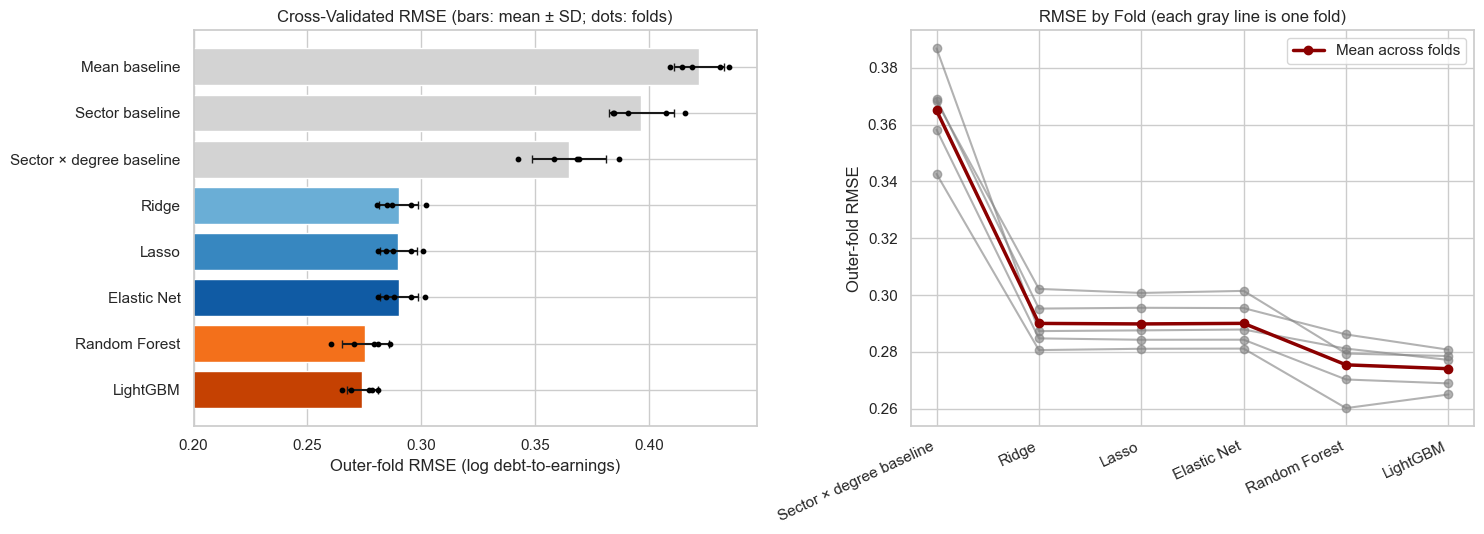

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

model_colors = (["lightgray"] * 3 + list(sns.color_palette("Blues", 5)[2:])
                + list(sns.color_palette("Oranges", 4)[2:]))
positions = np.arange(len(MODEL_ORDER))[::-1]
axes[0].barh(positions, comparison["rmse_mean"], xerr=comparison["rmse_std"],
             color=model_colors, capsize=3)
for pos, name in zip(positions, MODEL_ORDER):
    axes[0].scatter(rmse_by_fold[name], np.full(N_FOLDS, pos), color="black", s=10, zorder=3)
axes[0].set_yticks(positions, MODEL_ORDER)
axes[0].set_xlim(0.2, comparison["rmse_mean"].max() * 1.06)
axes[0].set_xlabel("Outer-fold RMSE (log debt-to-earnings)")
axes[0].set_ylabel("")
axes[0].set_title("Cross-Validated RMSE (bars: mean ± SD; dots: folds)")

for fold in range(N_FOLDS):
    axes[1].plot(MODEL_ORDER[2:], rmse_by_fold.loc[fold, MODEL_ORDER[2:]],
                 marker="o", color="gray", alpha=0.6)
axes[1].plot(MODEL_ORDER[2:], rmse_by_fold[MODEL_ORDER[2:]].mean(), marker="o",
             color="darkred", lw=2.5, label="Mean across folds")
axes[1].set_ylabel("Outer-fold RMSE")
axes[1].set_title("RMSE by Fold (each gray line is one fold)")
plt.setp(axes[1].get_xticklabels(), rotation=25, ha="right")
axes[1].legend()

fig.tight_layout()
save_figure(fig, "model_comparison")
plt.show()

### What the Comparison Presents

- **Every learned model beats every baseline in every fold**.
- **Tree ensembles beat the linear models.**
- **LightGBM and Random Forest are almost indistinguishable.** 

**LightGBM is selected** as the supervised model since it has the lowest mean RMSE
and the smallest fold-to-fold variation.

## 8. Selected Model

The selected model is refit on the full training set. Its hyperparameters are
re-tuned with the inner-CV search on all 2,636 training institutions; these
final hyperparameters are the ones saved for the integration and final
evaluation notebooks.

The out-of-fold predictions used in the diagnostics below come from the nested
cross-validation, so every institution is predicted by a model that never saw
it during fitting or tuning.

In [ ]:
SELECTED_MODEL = 'LightGBM'

final_search = clone(SEARCHES[SELECTED_MODEL]).fit(X, y)
final_model = final_search.best_estimator_
final_params = {k.replace("model__", ""): v for k, v in final_search.best_params_.items()}

print(f"Selected model: {SELECTED_MODEL}")
print(f"Inner-CV RMSE on the full training set: {-final_search.best_score_:.4f}")
print("Final hyperparameters:")
for key, value in final_params.items():
    print(f"  {key}: {value}")

train["oof_pred"] = oof_predictions[SELECTED_MODEL]
train["residual"] = train[TARGET] - train["oof_pred"]
oof_rmse = root_mean_squared_error(train[TARGET], train["oof_pred"])
oof_r2 = r2_score(train[TARGET], train["oof_pred"])
print(f"\nPooled out-of-fold RMSE: {oof_rmse:.4f}   R²: {oof_r2:.3f}")
print(f"Typical multiplicative error in the debt-to-earnings ratio: "
      f"×/÷ {np.exp(oof_rmse):.2f} (RMSE), ×/÷ {np.exp(train['residual'].abs().mean()):.2f} (MAE)")

Selected model: LightGBM
Inner-CV RMSE on the full training set: 0.2729
Final hyperparameters:
  colsample_bytree: 0.4305629572798979
  learning_rate: 0.0056496258399535565
  min_child_samples: 29
  n_estimators: 963
  num_leaves: 39
  reg_lambda: 0.001186494478357996
  subsample: 0.7560465291496405

Pooled out-of-fold RMSE: 0.2742   R²: 0.578
Typical multiplicative error in the debt-to-earnings ratio: ×/÷ 1.32 (RMSE), ×/÷ 1.22 (MAE)


### Predicted vs. Actual and Residuals

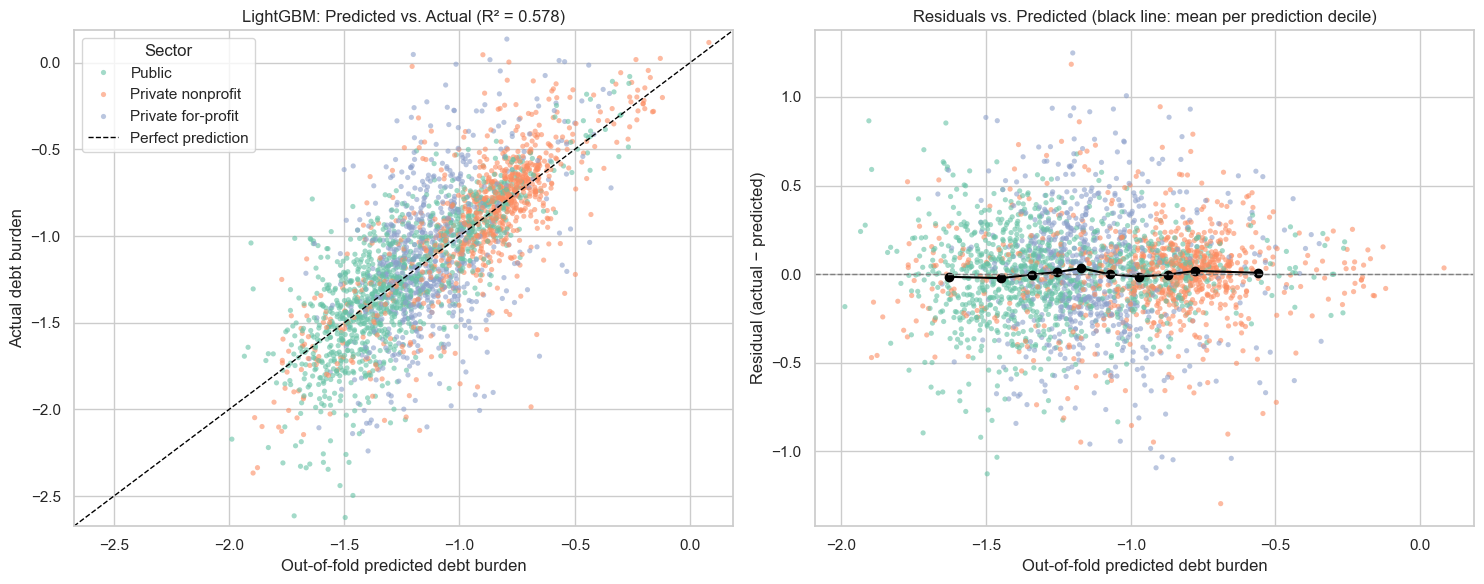

Residual mean: 0.0011
Residual skewness: -0.138
Correlation of residual with prediction: 0.021
SD of predictions: 0.315  vs. SD of actual: 0.422


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(data=train, x="oof_pred", y=TARGET, hue="SECTOR", hue_order=SECTOR_ORDER,
                palette=SECTOR_PALETTE, s=14, alpha=0.6, linewidth=0, ax=axes[0])
lims = [min(train[TARGET].min(), train["oof_pred"].min()) - 0.05,
        max(train[TARGET].max(), train["oof_pred"].max()) + 0.05]
axes[0].plot(lims, lims, color="black", ls="--", lw=1, label="Perfect prediction")
axes[0].set_xlim(lims)
axes[0].set_ylim(lims)
axes[0].set_xlabel("Out-of-fold predicted debt burden")
axes[0].set_ylabel("Actual debt burden")
axes[0].set_title(f"{SELECTED_MODEL}: Predicted vs. Actual (R² = {oof_r2:.3f})")
axes[0].legend(title="Sector", loc="upper left")

sns.scatterplot(data=train, x="oof_pred", y="residual", hue="SECTOR", hue_order=SECTOR_ORDER,
                palette=SECTOR_PALETTE, s=14, alpha=0.6, linewidth=0, legend=False, ax=axes[1])
# Mean residual within prediction deciles shows any systematic bias
bins = pd.qcut(train["oof_pred"], 10)
binned = train.groupby(bins, observed=True)[["oof_pred", "residual"]].mean()
axes[1].plot(binned["oof_pred"], binned["residual"], marker="o", color="black", lw=1.5)
axes[1].axhline(0, color="gray", ls="--", lw=1)
axes[1].set_xlabel("Out-of-fold predicted debt burden")
axes[1].set_ylabel("Residual (actual − predicted)")
axes[1].set_title("Residuals vs. Predicted (black line: mean per prediction decile)")

fig.tight_layout()
save_figure(fig, "predicted_vs_actual")
plt.show()

print(f"Residual mean: {train['residual'].mean():.4f}")
print(f"Residual skewness: {train['residual'].skew():.3f}")
print(f"Correlation of residual with prediction: {train[['residual', 'oof_pred']].corr().iloc[0, 1]:.3f}")
print(f"SD of predictions: {train['oof_pred'].std():.3f}  vs. SD of actual: {train[TARGET].std():.3f}")

**On the ratio scale, a typical prediction is off by a factor of about 1.2
(MAE) to 1.3 (RMSE).** For an institution whose true debt-to-earnings ratio is
0.33, a typical prediction lies between roughly 0.27 and 0.40.

- **No systematic bias across the range.** The mean residual within each decile
  of predictions stays near zero, and residuals are uncorrelated with the
  predictions (r = 0.02).
- **Predictions are compressed toward the mean.** The predictions have a
  standard deviation of 0.32 against 0.42 for the actual values.
- **Residuals are roughly symmetric**

### Errors Across Institution Types
The table below reports out-of-fold RMSE, MAE, and mean residual (bias) by sector and by
predominant degree. A positive bias means the model under-predicts burden for
that group. R² within each group shows how well the model ranks institutions
that share a sector or degree level.

Institutions per predominant degree: {'Certificate': 840, 'Associate': 583, "Bachelor's": 1212, 'Graduate': 1}


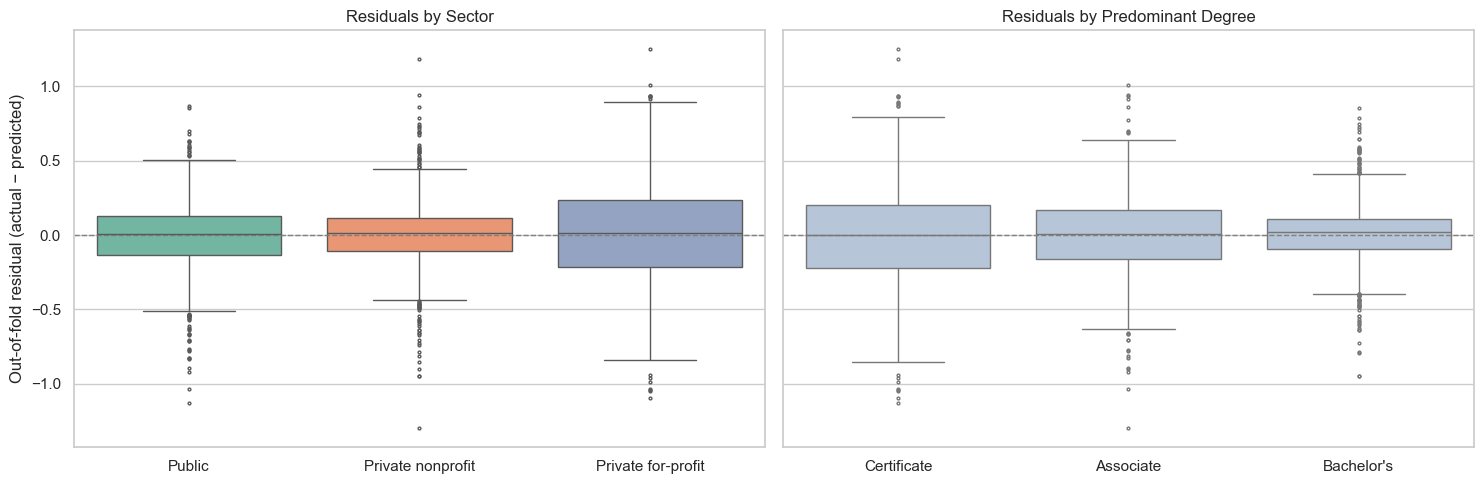

In [ ]:
def group_errors(groups, min_size=20):
    # Error summary for each group with at least 20 institutions
    rows = {}
    for name, sub in train.groupby(groups, observed=True):
        if len(sub) < min_size:
            continue
        rows[name] = {
            "n": len(sub),
            "rmse": root_mean_squared_error(sub[TARGET], sub["oof_pred"]),
            "mae": mean_absolute_error(sub[TARGET], sub["oof_pred"]),
            "bias": sub["residual"].mean(),
            "within_group_r2": r2_score(sub[TARGET], sub["oof_pred"]),
            "target_sd": sub[TARGET].std(),
        }
    return pd.DataFrame(rows).T


errors_by_sector = group_errors("SECTOR").loc[SECTOR_ORDER]
errors_by_degree = group_errors("DEGREE").reindex(DEGREE_ORDER).dropna(how="all")
print("Institutions per predominant degree:",
      train["DEGREE"].value_counts().reindex(DEGREE_ORDER).fillna(0).astype(int).to_dict())
errors_by_type = pd.concat({"Sector": errors_by_sector, "Predominant degree": errors_by_degree})
errors_by_type.to_csv(RESULTS_DIR / "errors_by_institution_type.csv")

display(errors_by_type.style.format({
    "n": "{:.0f}", "rmse": "{:.3f}", "mae": "{:.3f}", "bias": "{:+.3f}",
    "within_group_r2": "{:.3f}", "target_sd": "{:.3f}",
}))

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
sns.boxplot(data=train, x="SECTOR", y="residual", order=SECTOR_ORDER, hue="SECTOR",
            palette=SECTOR_PALETTE, legend=False, fliersize=2, ax=axes[0])
sns.boxplot(data=train, x="DEGREE", y="residual", order=list(errors_by_degree.index),
            color="lightsteelblue", fliersize=2, ax=axes[1])
for ax, title in zip(axes, ["Residuals by Sector", "Residuals by Predominant Degree"]):
    ax.axhline(0, color="gray", ls="--", lw=1)
    ax.set_xlabel("")
    ax.set_title(title)
axes[0].set_ylabel("Out-of-fold residual (actual − predicted)")
fig.tight_layout()
save_figure(fig, "residuals_by_institution_type")
plt.show()

In [ ]:
# Largest out-of-fold errors, with a few descriptive characteristics
largest_errors = (
    train.assign(abs_residual=train["residual"].abs())
    .nlargest(12, "abs_residual")
    [[ID_COL, "SECTOR", "DEGREE", "UGDS", "NUM_PROGRAMS", "NET_PRICE", "PCTFLOAN",
      TARGET, "oof_pred", "residual"]]
)
display(largest_errors.round(3))

print("Share of institutions with |residual| > 0.5:",
      f"{(train['residual'].abs() > 0.5).mean():.1%}")
print("Median enrollment, |residual| > 0.5:",
      train.loc[train["residual"].abs() > 0.5, "UGDS"].median(),
      "| all institutions:", train["UGDS"].median())

KeyError: 'residual'

### Where the Selected Model Struggles

- **For-profit and certificate institutions are much harder to predict.**
  
- **Errors are unbiased in every group** 
- **The largest errors are small, narrow institutions.** 

Only one training institution has a predominantly graduate degree, so that
group is excluded.

## 9. What Drives the Predictions?

Three complementary views are used:

1. **Permutation importance** on the *validation* part of each outer fold: how
   much RMSE rises when one predictor is shuffled. Because it is measured on
   held-out rows, it reflects predictive value rather than in-sample fit.
2. **SHAP values** for the final LightGBM model: the direction and size of each
   feature's contribution to individual predictions.
3. **Elastic Net coefficients**: the linear model's view of each feature's
   direction, for comparison with the non-linear model.

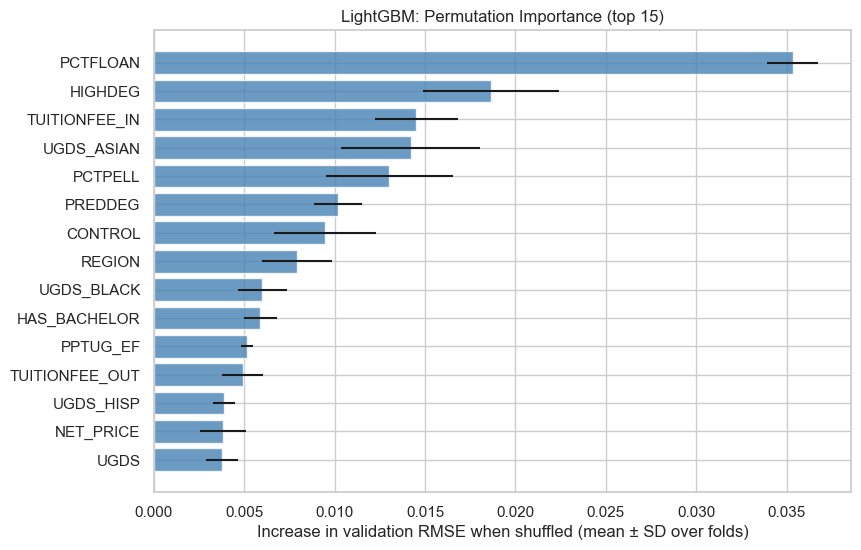

Features whose shuffling changes RMSE by less than 0.001: ['UGDS_NHPI', 'NUM_CREDENTIAL_LEVELS', 'HAS_FIRST_PROFESSIONAL', 'NUMBRANCH', 'HAS_DOCTORAL', 'HAS_MASTER', 'HAS_ASSOCIATE', 'COST_IS_ACADEMIC_YEAR', 'UGDS_UNKN', 'HAS_CERTIFICATE', 'HAS_GRAD_CERT', 'HAS_POSTBACC_CERT']


In [24]:
outer_estimators = cross_validate(
    clone(final_model), X, y, cv=OUTER_CV, return_estimator=True
)["estimator"]

importance_rows = []
for fold, (est, (_, valid_idx)) in enumerate(zip(outer_estimators, OUTER_CV.split(X))):
    result = permutation_importance(
        est, X.iloc[valid_idx], y.iloc[valid_idx], n_repeats=10,
        scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=-1,
    )
    importance_rows.append(pd.Series(result.importances_mean, index=FEATURES, name=fold))

perm_importance = pd.concat(importance_rows, axis=1)
perm_summary = pd.DataFrame({
    "rmse_increase_mean": perm_importance.mean(axis=1),
    "rmse_increase_std": perm_importance.std(axis=1),
}).sort_values("rmse_increase_mean", ascending=False)
perm_summary.to_csv(RESULTS_DIR / "permutation_importance.csv")

top = perm_summary.head(15)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index[::-1], top["rmse_increase_mean"][::-1],
        xerr=top["rmse_increase_std"][::-1], color="steelblue", alpha=0.8)
ax.set_xlabel("Increase in validation RMSE when shuffled (mean ± SD over folds)")
ax.set_title(f"{SELECTED_MODEL}: Permutation Importance (top 15)")
save_figure(fig, "permutation_importance")
plt.show()

print("Features whose shuffling changes RMSE by less than 0.001:",
      perm_summary.index[perm_summary["rmse_increase_mean"] < 0.001].tolist())

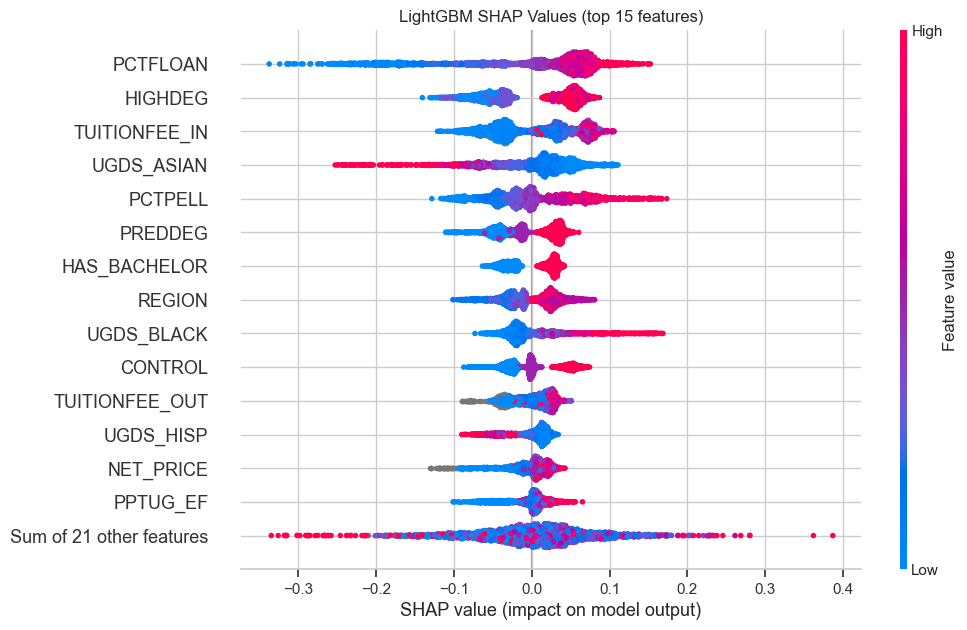

In [25]:
# SHAP is computed for the LightGBM model refit on the full training set.
if SELECTED_MODEL == "LightGBM":
    shap_model = final_model
else:
    shap_model = clone(SEARCHES["LightGBM"]).fit(X, y).best_estimator_
lgbm = shap_model.named_steps["model"]

explainer = shap.TreeExplainer(lgbm)
shap_values = explainer(X)

shap_importance = pd.Series(np.abs(shap_values.values).mean(axis=0), index=FEATURES)
shap_importance = shap_importance.sort_values(ascending=False)
shap_importance.rename("mean_abs_shap").to_csv(RESULTS_DIR / "shap_importance.csv")

plt.figure()
shap.plots.beeswarm(shap_values, max_display=15, show=False)
fig = plt.gcf()
fig.set_size_inches(10, 7)
plt.title("LightGBM SHAP Values (top 15 features)")
save_figure(fig, "shap_beeswarm")
plt.show()

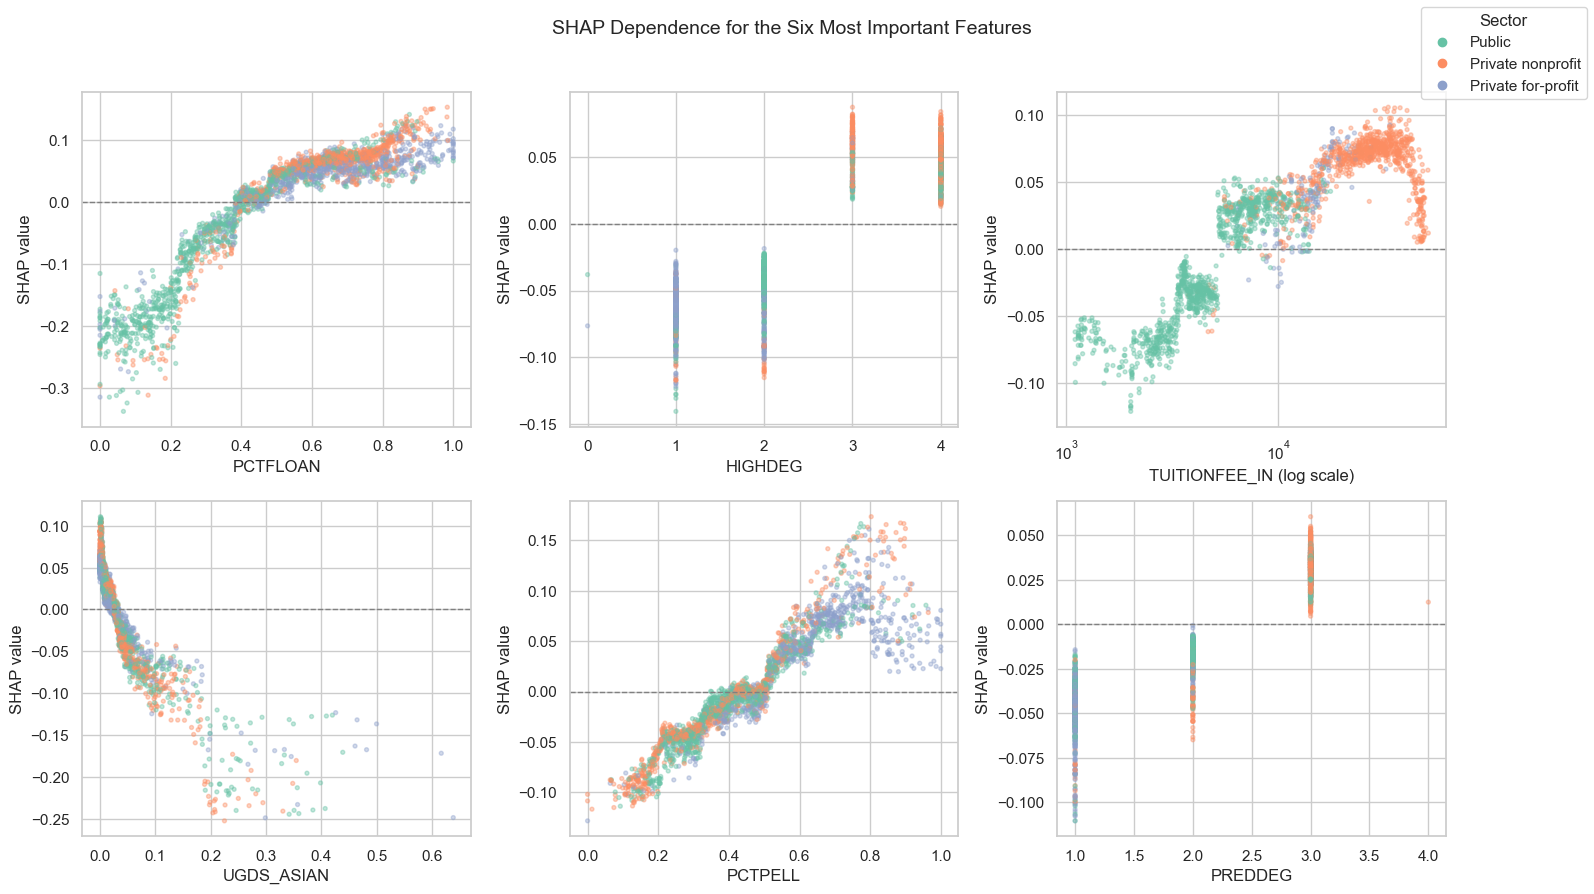

In [26]:
top_shap = shap_importance.index[:6]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, feature in zip(axes.flat, top_shap):
    x_values = X[feature]
    log_axis = feature in LOG_COLS
    ax.scatter(x_values, shap_values[:, feature].values, s=8, alpha=0.4,
               c=train["CONTROL"].map(dict(zip(SECTOR_LABELS, SECTOR_PALETTE.values()))).tolist())
    if log_axis:
        ax.set_xscale("log")
    ax.axhline(0, color="gray", ls="--", lw=1)
    ax.set_xlabel(feature + (" (log scale)" if log_axis else ""))
    ax.set_ylabel("SHAP value")
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=s) for s, c in SECTOR_PALETTE.items()]
fig.legend(handles=handles, title="Sector", loc="upper right")
fig.suptitle("SHAP Dependence for the Six Most Important Features", fontsize=14)
fig.tight_layout(rect=[0, 0, 0.92, 0.96])
save_figure(fig, "shap_dependence")
plt.show()

Elastic Net hyperparameters: 0.001 alpha, 0.9 l1_ratio
Non-zero coefficients: 46 of 63


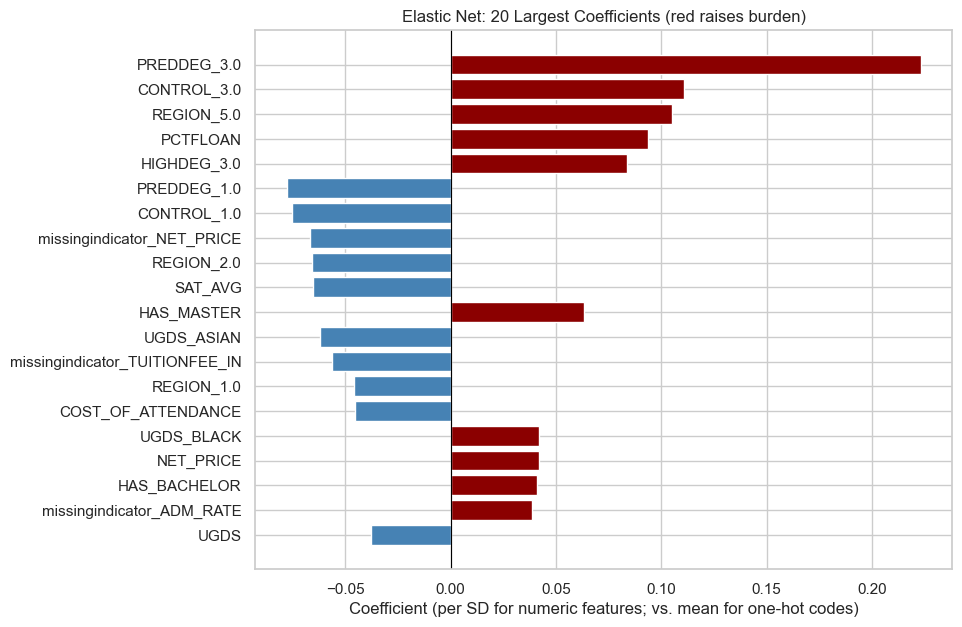

In [27]:
enet = clone(SEARCHES["Elastic Net"]).fit(X, y).best_estimator_
coefficients = pd.Series(
    enet.named_steps["model"].coef_,
    index=enet.named_steps["prep"].get_feature_names_out(),
)
print("Elastic Net hyperparameters:", enet.named_steps["model"].get_params()["alpha"].round(5),
      "alpha,", enet.named_steps["model"].get_params()["l1_ratio"], "l1_ratio")
print(f"Non-zero coefficients: {(coefficients != 0).sum()} of {len(coefficients)}")

top_coef = coefficients[coefficients.abs().sort_values(ascending=False).index[:20]]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top_coef.index[::-1], top_coef[::-1],
        color=["darkred" if v > 0 else "steelblue" for v in top_coef[::-1]])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Coefficient (per SD for numeric features; vs. mean for one-hot codes)")
ax.set_title("Elastic Net: 20 Largest Coefficients (red raises burden)")
save_figure(fig, "elastic_net_coefficients")
plt.show()

### Interpreting the Drivers

Permutation importance and SHAP agree on the main drivers:

1. **Federal loan participation (`PCTFLOAN`)**
2. **Degree level (`HIGHDEG`, `PREDDEG`, `HAS_BACHELOR`).** 
3. **Price (`TUITIONFEE_IN`).** 
4. **Student composition.** 
5. **Sector and region (`CONTROL`, `REGION`).** 


The individual program indicators (`HAS_MASTER`, `HAS_DOCTORAL`, …),
`NUM_CREDENTIAL_LEVELS`, and `NUMBRANCH` add almost nothing once `HIGHDEG` and
`PREDDEG` are in the model.

## 10. Learning Curves

Learning curves show whether more institutions would be likely to help. Each
model is refit with its final hyperparameters on growing subsets of each outer
training fold and scored on the corresponding validation fold. 

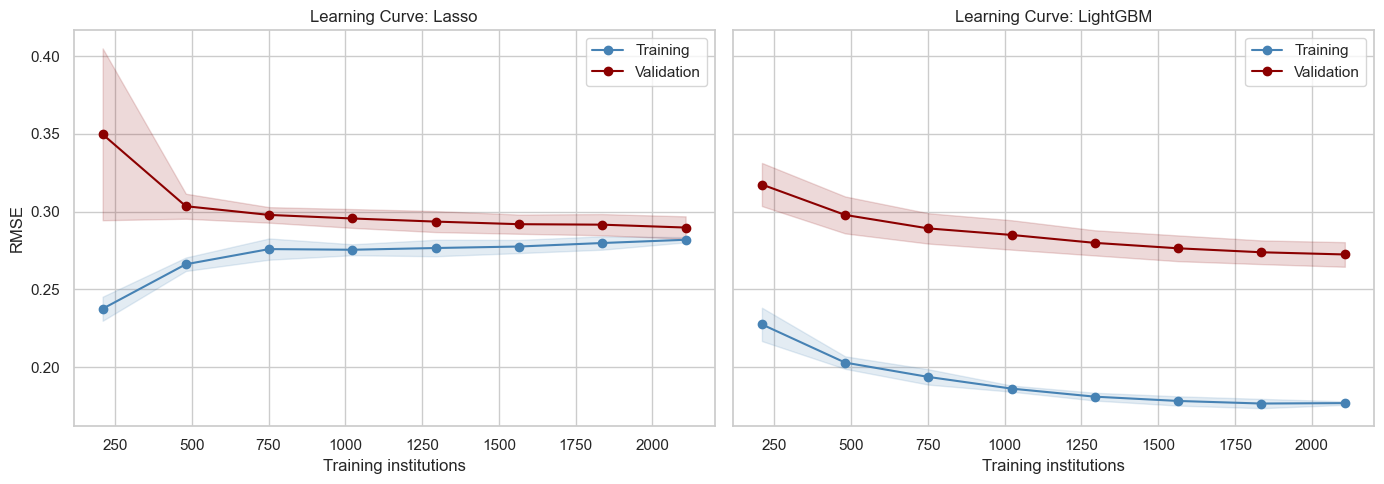

,model,train_size,train_rmse,validation_rmse
0,Lasso,210,0.2376,0.3497
1,Lasso,481,0.2662,0.3035
2,Lasso,752,0.2760,0.2979
3,Lasso,1023,0.2755,0.2956
4,Lasso,1294,0.2766,0.2936
5,Lasso,1565,0.2776,0.2920
6,Lasso,1836,0.2799,0.2917
7,Lasso,2108,0.2820,0.2898
8,LightGBM,210,0.2275,0.3175
9,LightGBM,481,0.2030,0.2979


In [28]:
best_linear = comparison.loc[["Ridge", "Lasso", "Elastic Net"], "rmse_mean"].idxmin()
curve_models = {best_linear: clone(SEARCHES[best_linear]).fit(X, y).best_estimator_}
if SELECTED_MODEL != best_linear:
    curve_models[SELECTED_MODEL] = final_model

fig, axes = plt.subplots(1, len(curve_models), figsize=(7 * len(curve_models), 5), sharey=True)
axes = np.atleast_1d(axes)
curve_rows = []
for ax, (name, model) in zip(axes, curve_models.items()):
    sizes, train_scores, valid_scores = learning_curve(
        clone(model), X, y, cv=OUTER_CV, train_sizes=np.linspace(0.1, 1.0, 8),
        scoring="neg_root_mean_squared_error", n_jobs=-1, shuffle=True,
        random_state=RANDOM_STATE,
    )
    for label, s, color in [("Training", -train_scores, "steelblue"),
                            ("Validation", -valid_scores, "darkred")]:
        ax.plot(sizes, s.mean(axis=1), marker="o", color=color, label=label)
        ax.fill_between(sizes, s.mean(axis=1) - s.std(axis=1),
                        s.mean(axis=1) + s.std(axis=1), color=color, alpha=0.15)
    curve_rows.append(pd.DataFrame({
        "model": name, "train_size": sizes,
        "train_rmse": -train_scores.mean(axis=1), "validation_rmse": -valid_scores.mean(axis=1),
    }))
    ax.set_title(f"Learning Curve: {name}")
    ax.set_xlabel("Training institutions")
    ax.legend()
axes[0].set_ylabel("RMSE")
fig.tight_layout()
save_figure(fig, "learning_curves")
plt.show()

curves = pd.concat(curve_rows, ignore_index=True)
curves.to_csv(RESULTS_DIR / "learning_curves.csv", index=False)
display(curves.round(4))

- **Lasso (the best linear model) has plateaued.** Its training and validation
  RMSE converge near 0.28–0.29 by about 1,000 institutions. More data will not help
- **LightGBM is still improving.** Validation RMSE falls from 0.280 at 1,300
  institutions to 0.273 at 2,100, and the gap between training (0.18) and
  validation (0.27) error shows remaining variance and more institutions would
  likely bring a small further gain.

## 11. Feature-Set Sensitivity

Two questions about the feature set are checked by refitting the selected
model, with its final hyperparameters fixed, on the same outer folds:

- **Without `ADM_RATE` and `SAT_AVG`:** these were dropped from the clustering
  analysis because of missingness.
- **Without `CONTROL`:** 

Hyperparameters are not re-tuned, so these results are a sensitivity check.

In [38]:
LINEAR_MODELS = ["Ridge", "Lasso", "Elastic Net"]

ablations = {
    "All features": [],
    "Without ADM_RATE, SAT_AVG": ["ADM_RATE", "SAT_AVG"],
    "Without CONTROL": ["CONTROL"],
}

ablation_rows = []
for label, columns in ablations.items():
    keep = [c for c in FEATURES if c not in columns]
    if SELECTED_MODEL in LINEAR_MODELS:
        model = linear_pipeline(clone(final_model.named_steps["model"]), features=keep)
    else:
        model = clone(final_model)
    cv = cross_validate(model, X[keep], y, cv=OUTER_CV, scoring=SCORING)
    ablation_rows.append({
        "feature_set": label,
        "rmse_mean": -cv["test_rmse"].mean(),
        "rmse_std": cv["test_rmse"].std(ddof=1),
        "r2_mean": cv["test_r2"].mean(),
    })

ablation = pd.DataFrame(ablation_rows).set_index("feature_set")
ablation["rmse_change"] = ablation["rmse_mean"] - ablation.loc["All features", "rmse_mean"]
ablation.to_csv(RESULTS_DIR / "feature_set_sensitivity.csv")
display(ablation.round(4))

,rmse_mean,rmse_std,r2_mean,rmse_change
feature_set,,,,
All features,0.2723,0.0098,0.5828,0.0000
"Without ADM_RATE, SAT_AVG",0.2738,0.0092,0.5781,0.0015
Without CONTROL,0.2747,0.0104,0.5753,0.0024


Both changes cost very little:

- **Dropping `ADM_RATE` and `SAT_AVG` raises RMSE by only 0.0015.** Selectivity
  data are missing for most institutions,
- **Dropping `CONTROL` raises RMSE by only 0.0024.** The other
  characteristics (price, loan participation, degree level, part-time share)
  already encode most of what the sector label says about burden.

With fixed hyperparameters, the full model scores 0.272, slightly below
its nested-CV score of 0.274.

## 12. Save the Selected Pipeline

- the fitted selected pipeline (`selected_model.joblib`), refit on the full
  training set;
- its name, hyperparameters, and cross-validation scores
  (`selected_model.json`), from which the unfitted pipeline can be rebuilt
  inside new cross-validation folds;
- the final hyperparameters of every tuned model (`tuned_hyperparameters.json`);
- the out-of-fold predictions of every model (`oof_predictions.csv`).

In [30]:
def to_builtin(value):
    # Convert numpy scalars so the parameters can be written to JSON
    return value.item() if isinstance(value, np.generic) else value


joblib.dump(final_model, RESULTS_DIR / "selected_model.joblib")

tuned_params = {SELECTED_MODEL: final_params}
for name in ["Ridge", "Lasso", "Elastic Net", "Random Forest", "LightGBM"]:
    if name not in tuned_params:
        search = clone(SEARCHES[name]).fit(X, y)
        tuned_params[name] = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
tuned_params = {name: {k: to_builtin(v) for k, v in params.items()}
                for name, params in tuned_params.items()}
with open(RESULTS_DIR / "tuned_hyperparameters.json", "w") as f:
    json.dump(tuned_params, f, indent=2)

selected = {
    "model": SELECTED_MODEL,
    "hyperparameters": tuned_params[SELECTED_MODEL],
    "features": FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "log_features": LOG_COLS,
    "target": TARGET,
    "cv": {"n_splits": N_FOLDS, "shuffle": True, "random_state": RANDOM_STATE,
           "fold_file": "results/02_supervised/cv_folds.csv"},
    "nested_cv_rmse_mean": round(float(comparison.loc[SELECTED_MODEL, "rmse_mean"]), 4),
    "nested_cv_rmse_std": round(float(comparison.loc[SELECTED_MODEL, "rmse_std"]), 4),
    "nested_cv_mae_mean": round(float(comparison.loc[SELECTED_MODEL, "mae_mean"]), 4),
    "nested_cv_r2_mean": round(float(comparison.loc[SELECTED_MODEL, "r2_mean"]), 4),
    "baseline_rmse": {name: round(float(comparison.loc[name, "rmse_mean"]), 4)
                      for name in MODEL_ORDER[:3]},
}
with open(RESULTS_DIR / "selected_model.json", "w") as f:
    json.dump(selected, f, indent=2)

oof_out = pd.DataFrame(oof_predictions)[MODEL_ORDER]
oof_out.insert(0, "fold", fold_id)
oof_out.insert(0, TARGET, y.to_numpy())
oof_out.insert(0, ID_COL, train[ID_COL].to_numpy())
oof_out.to_csv(RESULTS_DIR / "oof_predictions.csv", index=False)

# The saved pipeline must reproduce the in-memory model exactly.
reloaded = joblib.load(RESULTS_DIR / "selected_model.joblib")
assert np.allclose(reloaded.predict(X), final_model.predict(X))

print(json.dumps({k: selected[k] for k in ["model", "hyperparameters", "nested_cv_rmse_mean",
                                           "nested_cv_r2_mean"]}, indent=2))
print("\nSaved:")
for path in sorted(RESULTS_DIR.glob("*")):
    print(" ", path.relative_to(PROJECT_ROOT).as_posix())

{
  "model": "LightGBM",
  "hyperparameters": {
    "colsample_bytree": 0.4305629572798979,
    "learning_rate": 0.0056496258399535565,
    "min_child_samples": 29,
    "n_estimators": 963,
    "num_leaves": 39,
    "reg_lambda": 0.001186494478357996,
    "subsample": 0.7560465291496405
  },
  "nested_cv_rmse_mean": 0.2741,
  "nested_cv_r2_mean": 0.5771
}

Saved:
  results/02_supervised/cv_folds.csv
  results/02_supervised/cv_scores_by_fold.csv
  results/02_supervised/errors_by_institution_type.csv
  results/02_supervised/feature_set_sensitivity.csv
  results/02_supervised/learning_curves.csv
  results/02_supervised/model_comparison.csv
  results/02_supervised/oof_predictions.csv
  results/02_supervised/permutation_importance.csv
  results/02_supervised/selected_model.joblib
  results/02_supervised/selected_model.json
  results/02_supervised/shap_importance.csv
  results/02_supervised/tuned_hyperparameters.json


## Summary

### Findings

1. **Debt burden is substantially predictable from pre-outcome
   characteristics.** The selected LightGBM model reaches a nested
   cross-validated RMSE of **0.274** (R² = **0.58**) on the log debt-to-earnings
   scale, against 0.422 for the mean baseline, 0.397 for sector means, and 0.365
   for sector × degree means. A typical prediction is within a factor of about
   1.2–1.3 of the true debt-to-earnings ratio.
2. **Non-Linear Models are better for this prediction.** LightGBM and Random Forest are tied
   (RMSE 0.274 and 0.275) and both beat Ridge, Lasso, and Elastic Net (0.290)
   in every fold. The gain comes largely from non-linear effects such as burden
   falling again at the highest tuition levels.
3. **Loan participation, degree level, price, and student composition drive
   the predictions.** `PCTFLOAN` is the dominant feature; bachelor's-level
   degrees, higher tuition (up to about \$30,000), higher Pell and Black
   enrollment shares, for-profit control, and the Southeast raise predicted
   burden.
4. **Accuracy is uneven across institution types.** The model is precise for
   bachelor's, public, and private nonprofit institutions (within-group R² up
   to 0.72) but much less so for small for-profit and certificate institutions
   (within-group R² ≈ 0.2), where the largest errors are concentrated.
5. **The model is robust to the feature set.** Dropping the heavily missing
   selectivity features or the sector label changes RMSE by less than 0.003.

### Limitations

- All results are cross-validated on the training set only. The held-out test
  set has not been used and will provide the final estimate
- `PCTFLOAN` is observed before the outcome, but its relationship to median
  debt is close to mechanical; the model's accuracy partly reflects that link.
- Importance measures describe associations within this model, not causal
  effects. Composition features in particular likely proxy for unobserved
  factors such as family resources and local labor markets.
- Institution-level medians are noisy for small institutions, which limits
  achievable accuracy for certificate schools.

### Outputs

| Output | Location |
|---|---|
| Shared outer CV folds (one per `OPEID6`) | `results/02_supervised/cv_folds.csv` |
| Selected model, hyperparameters, and CV scores | `results/02_supervised/selected_model.json` |
| Fitted selected pipeline (full training set) | `results/02_supervised/selected_model.joblib` |
| Final hyperparameters for every tuned model | `results/02_supervised/tuned_hyperparameters.json` |
| Per-fold scores and model comparison | `results/02_supervised/cv_scores_by_fold.csv`, `model_comparison.csv` |
| Out-of-fold predictions for every model | `results/02_supervised/oof_predictions.csv` |
| Error, importance, learning-curve, and sensitivity tables | `results/02_supervised/*.csv` |
| Figures | `figures/02_supervised/*.png` |
